# 02 — Fine-tuning en 3 classes : résultats et analyse

**Question** : un DistilCamemBERT fine-tuné directement en 3 classes corrige-t-il la classe neutre sans perdre la qualité en positif / négatif ?

**Protocole** (détails : [`docs/EXPERIMENTS.md`](../docs/EXPERIMENTS.md))
- entraînement : `tweets_fr_train` (1 839 tweets) ;
- choix de la meilleure époque : `tweets_fr_validation` (324 tweets) ;
- test, une seule fois à la fin : `tweets_fr_test` (870) et `textsense_eval_v1` (360).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REPORTS = ROOT / "reports"
pd.set_option("display.precision", 3)


def load_metrics(run, dataset):
    path = REPORTS / "eval" / run / dataset / "metrics.json"
    return json.loads(path.read_text())["metrics"] if path.exists() else None


def overview(runs, datasets):
    rows = []
    for run in runs:
        for dataset in datasets:
            m = load_metrics(run, dataset)
            if m is None:
                continue
            low, high = m["ci95"]["macro_f1"]
            rows.append({
                "modèle": run, "jeu": dataset, "macro-F1": m["macro_f1"],
                "IC 95 %": f"[{low:.3f} – {high:.3f}]", "exactitude": m["accuracy"],
                "F1 nég.": m["per_class"]["negative"]["f1"],
                "F1 neutre": m["per_class"]["neutral"]["f1"],
                "F1 pos.": m["per_class"]["positive"]["f1"], "ECE": m["ece"],
            })
    return pd.DataFrame(rows).set_index(["jeu", "modèle"]).sort_index()


def by_phenomenon(runs):
    data = {}
    for run in runs:
        m = load_metrics(run, "textsense_eval_v1")
        if m:
            data[run] = {k: v["accuracy"] for k, v in m["by_group"]["phenomenon"].items()}
    df = pd.DataFrame(data)
    counts = load_metrics(runs[0], "textsense_eval_v1")["by_group"]["phenomenon"]
    df.insert(0, "n", [counts[p]["n"] for p in df.index])
    return df


In [2]:
MAIN = "distilcamembert-3c-starinit-s42"
SEEDS = ["distilcamembert-3c-starinit-s42", "distilcamembert-3c-starinit-s13", "distilcamembert-3c-starinit-s7"]
ABLATIONS = ["distilcamembert-3c-randinit-s42", "distilcamembert-generic-3c-s42"]
BASELINES = ["baseline-stars", "tfidf-fallback"]

## Courbes d'entraînement

Perte d'entraînement et de validation, macro-F1 de validation par époque.

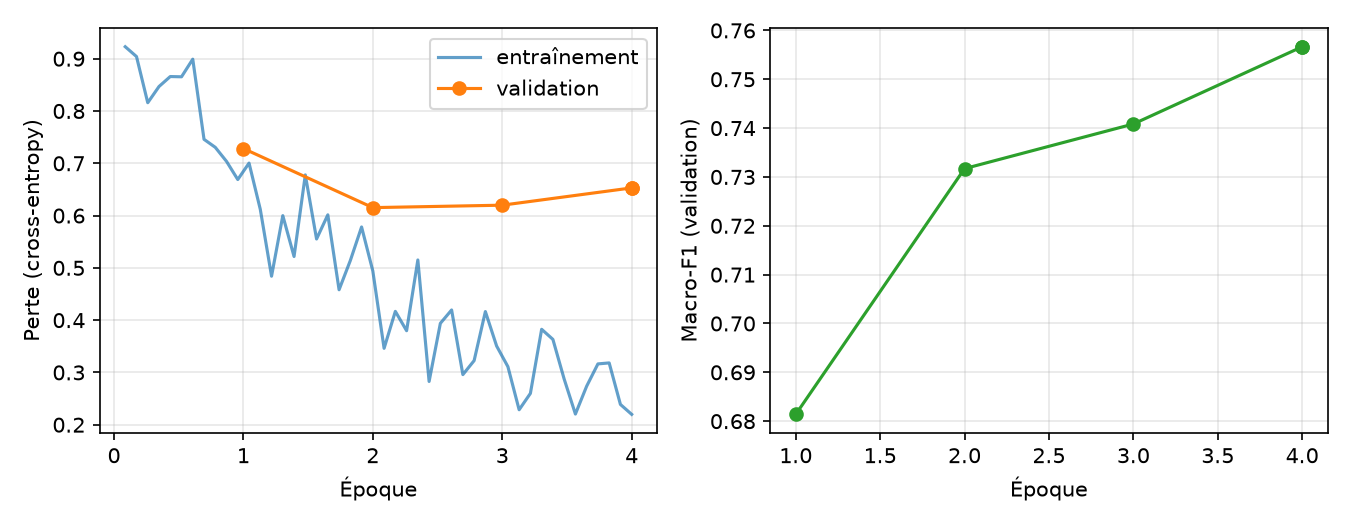

In [3]:
display(Image(filename=str(REPORTS / "training" / MAIN / "training_curves.png")))

## Comparaison avec les modèles de référence

In [4]:
overview(BASELINES + [MAIN], ["textsense_eval_v1", "tweets_fr_test"])

macro-F1          IC 95 %  \
jeu               modèle                                                       
textsense_eval_v1 baseline-stars                      0.510  [0.480 – 0.541]   
                  distilcamembert-3c-starinit-s42     0.885  [0.851 – 0.917]   
                  tfidf-fallback                      0.513  [0.462 – 0.564]   
tweets_fr_test    baseline-stars                      0.363  [0.335 – 0.390]   
                  distilcamembert-3c-starinit-s42     0.723  [0.692 – 0.754]   
                  tfidf-fallback                      0.264  [0.238 – 0.292]   

                                                   exactitude  F1 nég.  \
jeu               modèle                                                 
textsense_eval_v1 baseline-stars                        0.617    0.805   
                  distilcamembert-3c-starinit-s42       0.886    0.867   
                  tfidf-fallback                        0.542    0.481   
tweets_fr_test    baseline-stars                        0.438    0.507   
                  distilcamembert-3c-starinit-s42       0.724    0.792   
                  tfidf-fallback                        0.341    0.244   

                                                   F1 neutre  F1 pos.    ECE  
jeu               modèle                                                      
textsense_eval_v1 baseline-stars                       0.031    0.694  0.154  
                  distilcamembert-3c-starinit-s42      0.882    0.907  0.049  
                  tfidf-fallback                       0.651    0.407  0.033  
tweets_fr_test    baseline-stars                       0.052    0.529  0.167  
                  distilcamembert-3c-starinit-s42      0.696    0.681  0.146  
                  tfidf-fallback                       0.465    0.082  0.175

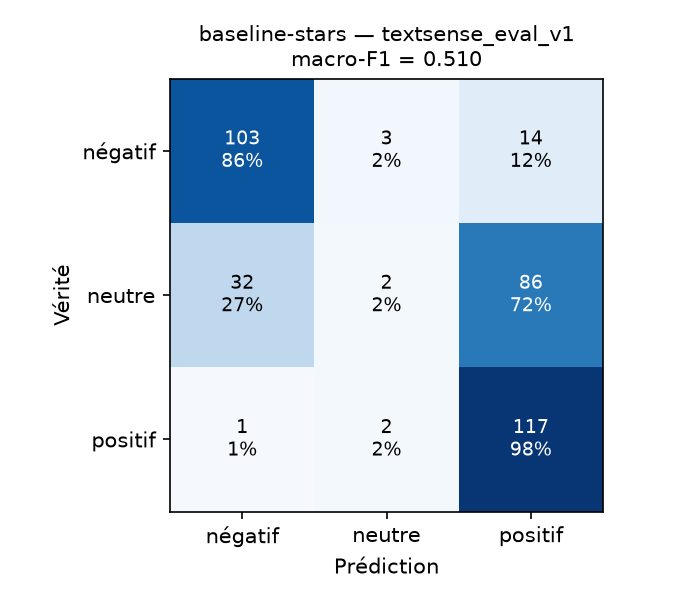

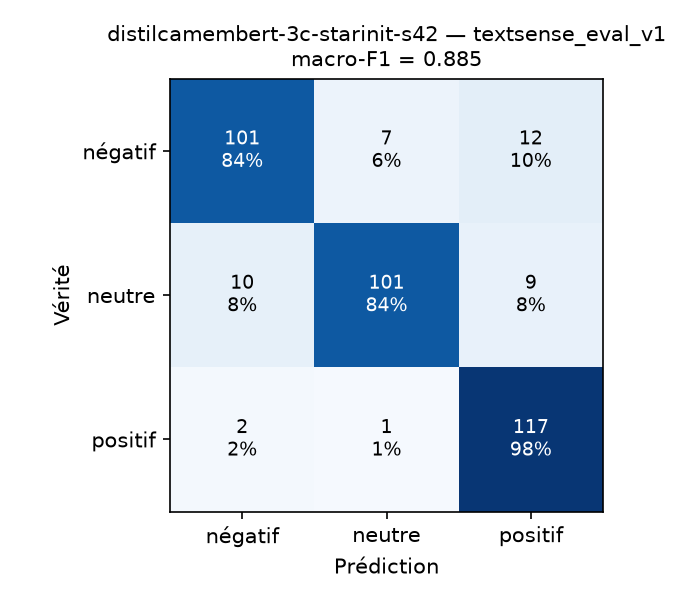

In [5]:
for run in ["baseline-stars", MAIN]:
    display(Image(filename=str(REPORTS / "eval" / run / "textsense_eval_v1" / "confusion_matrix.png"), width=360))

## Variance entre graines

Même configuration, trois graines aléatoires. L'écart-type indique quelle différence entre deux modèles peut être due au hasard de l'entraînement.

In [6]:
rows = []
for run in SEEDS:
    for dataset in ["textsense_eval_v1", "tweets_fr_test"]:
        m = load_metrics(run, dataset)
        if m:
            rows.append({"graine": run.rsplit("-s", 1)[1], "jeu": dataset, "macro-F1": m["macro_f1"],
                         "F1 neutre": m["per_class"]["neutral"]["f1"]})
seeds = pd.DataFrame(rows)
display(seeds.pivot(index="graine", columns="jeu", values="macro-F1"))
seeds.groupby("jeu")[["macro-F1", "F1 neutre"]].agg(["mean", "std"])

jeu,textsense_eval_v1,tweets_fr_test
graine,,
13,0.883,0.728
42,0.885,0.723
7,0.880,0.720


macro-F1        F1 neutre       
                      mean    std      mean    std
jeu                                               
textsense_eval_v1    0.883  0.003     0.874  0.009
tweets_fr_test       0.724  0.004     0.701  0.006

## Ablations

- `randinit` : même modèle de départ, tête 3 classes **aléatoire** (au lieu d'être initialisée depuis la tête « étoiles ») ;
- `generic` : DistilCamemBERT **générique**, jamais entraîné au sentiment.

In [7]:
overview([MAIN] + ABLATIONS, ["textsense_eval_v1", "tweets_fr_test"])

macro-F1          IC 95 %  \
jeu               modèle                                                       
textsense_eval_v1 distilcamembert-3c-randinit-s42     0.877  [0.844 – 0.911]   
                  distilcamembert-3c-starinit-s42     0.885  [0.851 – 0.917]   
                  distilcamembert-generic-3c-s42      0.783  [0.738 – 0.826]   
tweets_fr_test    distilcamembert-3c-randinit-s42     0.723  [0.692 – 0.754]   
                  distilcamembert-3c-starinit-s42     0.723  [0.692 – 0.754]   
                  distilcamembert-generic-3c-s42      0.743  [0.713 – 0.772]   

                                                   exactitude  F1 nég.  \
jeu               modèle                                                 
textsense_eval_v1 distilcamembert-3c-randinit-s42       0.878    0.860   
                  distilcamembert-3c-starinit-s42       0.886    0.867   
                  distilcamembert-generic-3c-s42        0.786    0.731   
tweets_fr_test    distilcamembert-3c-randinit-s42       0.723    0.788   
                  distilcamembert-3c-starinit-s42       0.724    0.792   
                  distilcamembert-generic-3c-s42        0.744    0.793   

                                                   F1 neutre  F1 pos.    ECE  
jeu               modèle                                                      
textsense_eval_v1 distilcamembert-3c-randinit-s42      0.874    0.897  0.026  
                  distilcamembert-3c-starinit-s42      0.882    0.907  0.049  
                  distilcamembert-generic-3c-s42       0.807    0.812  0.094  
tweets_fr_test    distilcamembert-3c-randinit-s42      0.696    0.684  0.123  
                  distilcamembert-3c-starinit-s42      0.696    0.681  0.146  
                  distilcamembert-generic-3c-s42       0.729    0.707  0.151

## Par phénomène linguistique (`textsense_eval_v1`)

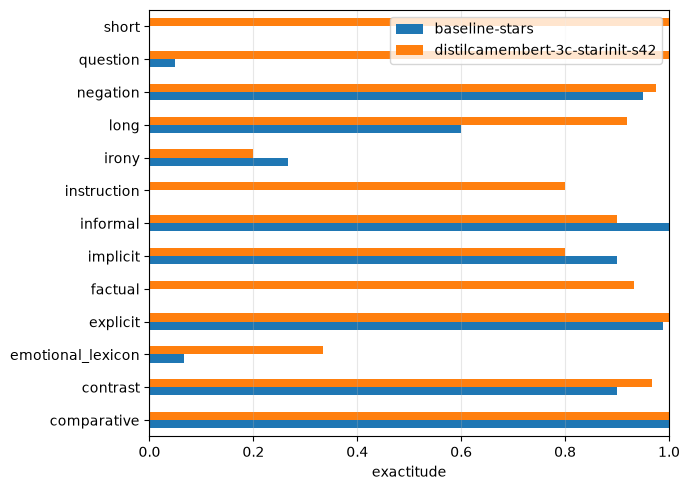

,n,baseline-stars,distilcamembert-3c-starinit-s42
comparative,10,1.000,1.000
contrast,30,0.900,0.967
emotional_lexicon,15,0.067,0.333
explicit,80,0.988,1.000
factual,45,0.000,0.933
implicit,30,0.900,0.800
informal,20,1.000,0.900
instruction,20,0.000,0.800
irony,15,0.267,0.200
long,25,0.600,0.920


In [8]:
table = by_phenomenon(["baseline-stars", MAIN])
ax = table.drop(columns='n').plot.barh(figsize=(7, 5))
ax.set_xlabel("exactitude"); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()
table

## Erreurs restantes du modèle fine-tuné

In [9]:
pred = pd.read_csv(REPORTS / "eval" / MAIN / "textsense_eval_v1" / "predictions.csv")
errors = pred[pred.label != pred.pred]
display(pd.crosstab(errors.label, errors.pred, rownames=["vérité"], colnames=["prédiction"]))
errors.sort_values("confidence", ascending=False)[["text", "label", "pred", "confidence", "phenomenon"]].head(15)

prédiction,negative,neutral,positive
vérité,,,
negative,0,7,12
neutral,10,0,9
positive,2,1,0


,text,label,pred,confidence,phenomenon
192,Quel plaisir de corriger les erreurs des autre...,negative,positive,0.992,irony
190,"Top, la chambre avec « vue sur mer » donne sur...",negative,positive,0.989,irony
187,Encore une réunion qui aurait pu être un e-mai...,negative,positive,0.987,irony
326,L'article analyse les causes de la colère des ...,neutral,negative,0.986,emotional_lexicon
184,"Merveilleux, l'appli me demande de me reconnec...",negative,positive,0.985,irony
333,Le mot « catastrophe » vient du grec ancien.,neutral,negative,0.982,emotional_lexicon
181,"Bravo, troisième retard du train cette semaine...",negative,positive,0.966,irony
182,"Super, mon colis « livré » est introuvable, me...",negative,positive,0.952,irony
338,Le journaliste a interrogé des supporters déçu...,neutral,positive,0.941,emotional_lexicon
180,"Génial, encore une panne de réseau en pleine r...",negative,positive,0.911,irony


## Seuil de confiance

Choisi sur la **validation** : le plus petit seuil tel que les prédictions au-dessus atteignent l'exactitude visée.

Seuil retenu : **0.81** (cible 85% sur `tweets_fr_validation`)

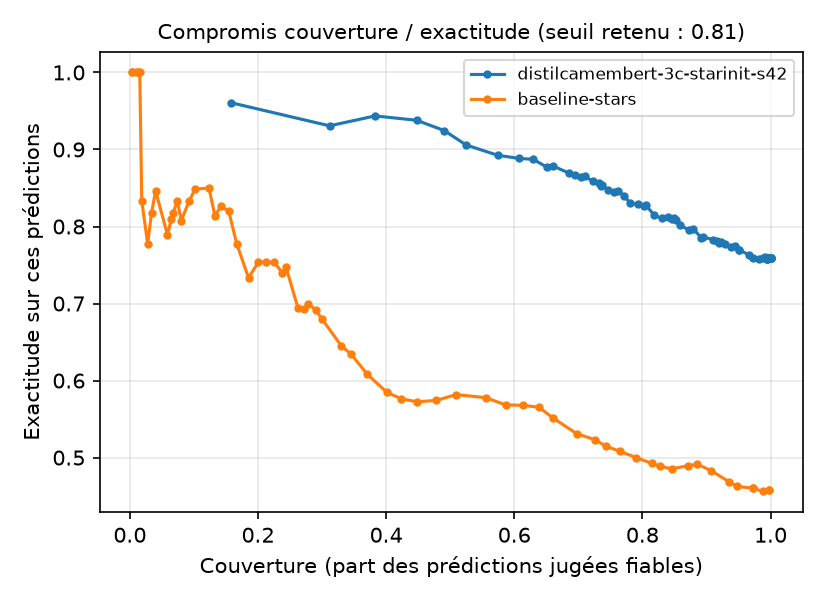

In [10]:
calibration = json.loads((REPORTS / "calibration" / f"{MAIN}.json").read_text())
display(Markdown(f"Seuil retenu : **{calibration['chosen']['threshold']:.2f}** "
                 f"(cible {calibration['target_accuracy']:.0%} sur `{calibration['dataset']}`)"))
display(Image(filename=str(REPORTS / "calibration" / f"{MAIN}.png"), width=480))

## Export ONNX

In [11]:
onnx = json.loads((REPORTS / "onnx" / f"{MAIN}.json").read_text())["results"]
pd.DataFrame({k: {
    "taille (Mo)": v["size_mb"], "latence p50 (ms)": v["latency_ms_single_text"]["p50"],
    "latence p95 (ms)": v["latency_ms_single_text"]["p95"],
    "accord avec PyTorch": v["agreement_with_pytorch"],
    "exactitude textsense_eval_v1": v["accuracy_textsense_eval_v1"],
} for k, v in onnx.items()}).T

,taille (Mo),latence p50 (ms),latence p95 (ms),accord avec PyTorch,exactitude textsense_eval_v1
pytorch_fp32,272.4,17.18,32.65,1.000,0.886
onnx_fp32,272.5,10.30,23.51,1.000,0.886
onnx_int8,68.7,4.38,10.08,0.958,0.883


## Conclusions

- **Classe neutre corrigée** : F1 neutre 0,03 → 0,88 sur `textsense_eval_v1` ; macro-F1 0,51 → 0,885 (intervalles de confiance disjoints). Sur les tweets de test : 0,36 → 0,72.
- **Acquis conservés** : négation et contraste restent à ~97 %.
- **Résultat stable** : 0,883 ± 0,003 sur trois graines.
- **Ablations** : initialiser la tête depuis les étoiles n'apporte rien (la tête aléatoire est même mieux calibrée) ; partir d'un modèle déjà spécialisé en sentiment est décisif hors domaine (+10 points sur `textsense_eval_v1`), alors que le modèle générique est un peu meilleur sur les tweets. Un seul jeu de test aurait conduit au mauvais choix.
- **Limites** : ironie (~20 %), textes décrivant une émotion sans jugement (~33 %).
- **ONNX int8 per-channel** : 4× plus léger et ~4× plus rapide, -0,3 point sur `textsense_eval_v1`, -1,8 point sur les tweets. La quantification per-tensor par défaut cassait le modèle (34 % d'exactitude) : toujours mesurer après quantification.